Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

Part 1: Analyzing Best-Seller Trends Across Product Categories

1.1. Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv("/Users/elenagarriguespascual/Desktop/Ironhack/WEEK5/amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df["category"].unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [6]:
df["isBestSeller"].value_counts()

isBestSeller
False    2435671
True        7980
Name: count, dtype: int64

In [7]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [10]:
pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
)

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [12]:
ratio = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
)[True]

ratio

category
3D Printers                       0.004032
3D Printing & Scanning            0.000492
Abrasive & Finishing Products     0.020000
Action Cameras                    0.000589
Adapters                          0.011811
                                    ...   
Wind Instruments                  0.028000
Window Treatments                 0.020921
Women                             0.011985
Women's Sports & Outdoor Shoes    0.010209
eBook Readers & Accessories       0.000000
Name: True, Length: 296, dtype: float64

In [13]:
ratio.sort_values(ascending=False)

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Name: True, Length: 296, dtype: float64

Are there categories where being a best-seller is more prevalent?

Yes, Grocery is the category where a best-seller is more prevalent, 5.8%, followed by Smart Home Security & Lighting, 5.7% and health & Personal Care, 5.7% as well, but slightly lower.

1.2. Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [14]:
from scipy.stats import chi2_contingency

chi2_contingency(crosstab)

Chi2ContingencyResult(statistic=np.float64(36540.20270061387), pvalue=np.float64(0.0), dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.017

H0 = Category and isBestSeller have no association.
H1 = Category and isBestSeller have an association between them.

Since the p-value is =np.float64(0.0), we can assume that H1 is correct, there is stadistical evidence of an association between them, for p-value < 0.05.

Compute Cramér's V to understand the strength of association between best-seller status and category.

In [15]:
from scipy.stats.contingency import association

association(crosstab, method = "cramer")

0.1222829439760564

Creamer's suggests that this association is weak, 0.122, very close to 0. Therefore, although product category is related to best-seller status, the relationship is not particularly strong.

1.3 Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

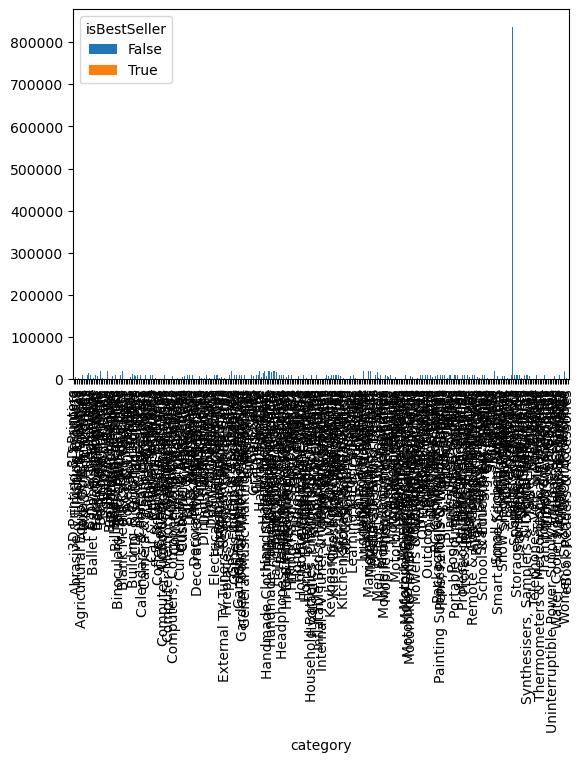

In [16]:
crosstab.plot(kind = "bar", stacked= True)

It is obvious that this graph is useless for an analysis, since we have 296 categories. Using a proportion will be much more useful and visually clear. As we concluded previously, Grocery is the category where a best-seller is more prevalent, 5.8%, followed by Smart Home Security & Lighting, 5.7% and health & Personal Care, 5.7% as well, but slightly lower.

In [17]:
ratio = (
    pd.crosstab(
        df["category"],
        df["isBestSeller"],
        normalize="index"
    )[True]
    .sort_values(ascending=False)
)

<Axes: xlabel='category'>

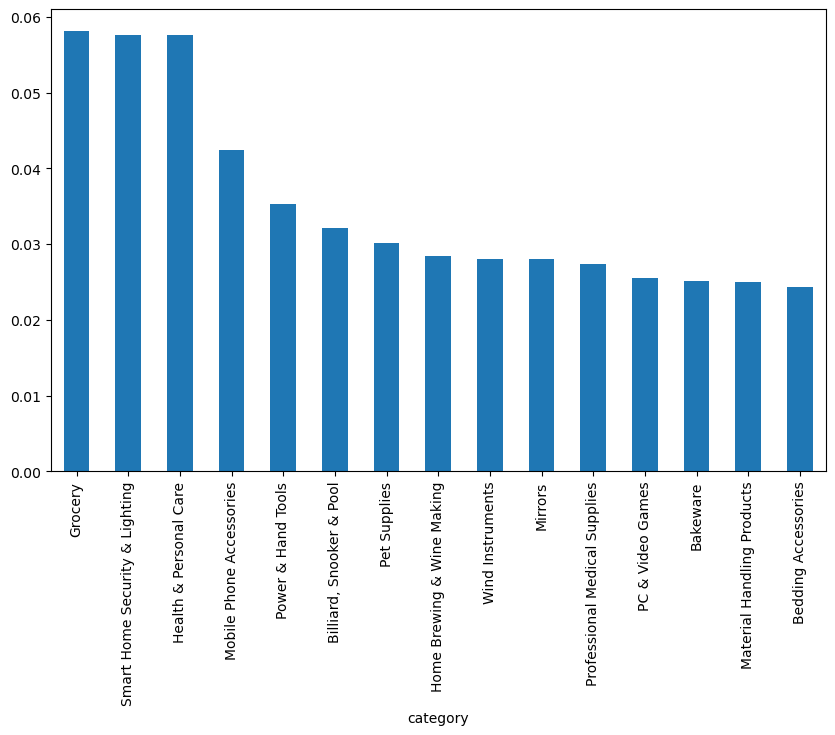

In [18]:
ratio.head(15).plot(kind="bar", figsize=(10,6))

Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Preliminary Step: Remove outliers in product prices.

In [19]:
df["price"].head()

0    21.99
1    23.99
2    21.99
3    31.99
4    17.99
Name: price, dtype: float64

In [48]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

In [50]:
df_no_outliers.shape

(2115963, 9)

In [28]:
df_no_outliers.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [25]:
df["price"].shape

(2443651,)

2.1. Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.

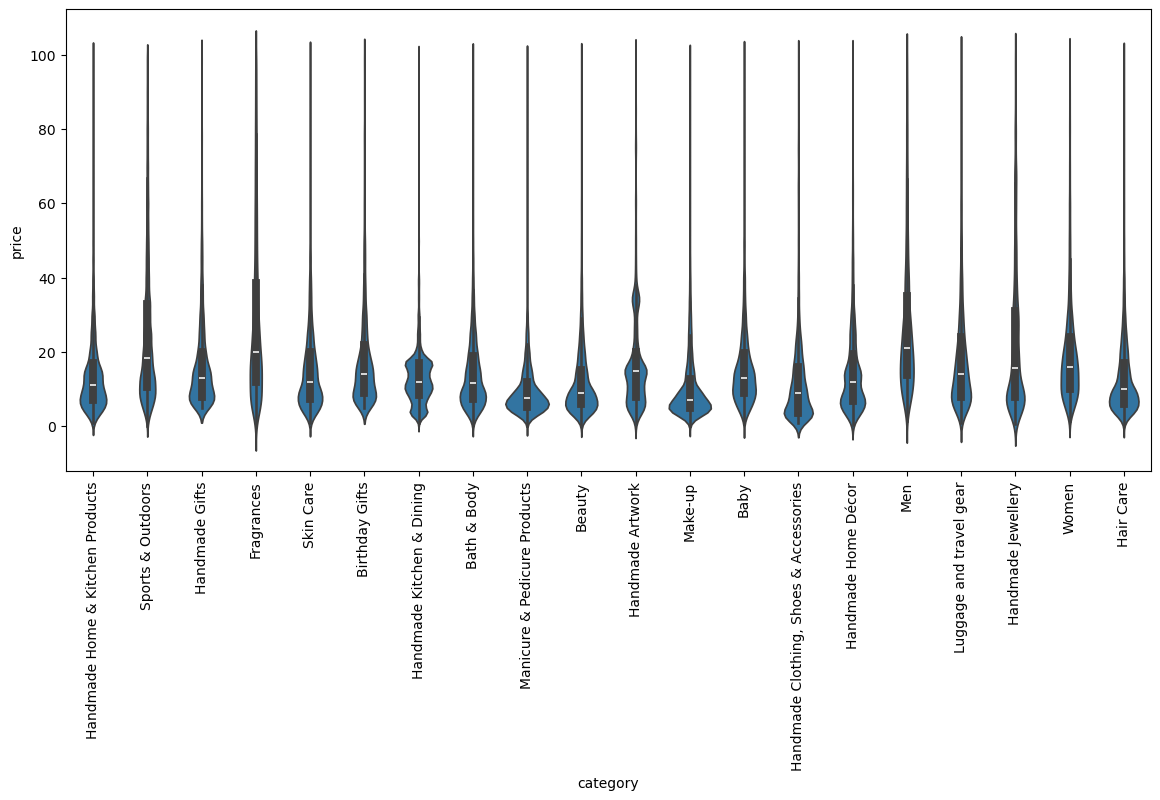

In [29]:
top20 = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20)]

plt.figure(figsize=(14,6))
sns.violinplot(
    data=df_top20,
    x="category",
    y="price"
)
plt.xticks(rotation=90)
plt.show()

In [30]:
median_price = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

Which product category tends to have the highest median price? Don't filter here by top categories.


The Desktop PCs category has the highest median price, 74, followed by Boxing Showes, 69.79, and Tablets, 69.

Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).


In [33]:
top10 = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)
top10

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [35]:
df_top10 = df_no_outliers[
    df_no_outliers["category"].isin(top10)
]
df_top10

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


In [38]:
avg_price = (
    df_top10
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)
avg_price

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

Text(0, 0.5, 'Average Price (£)')

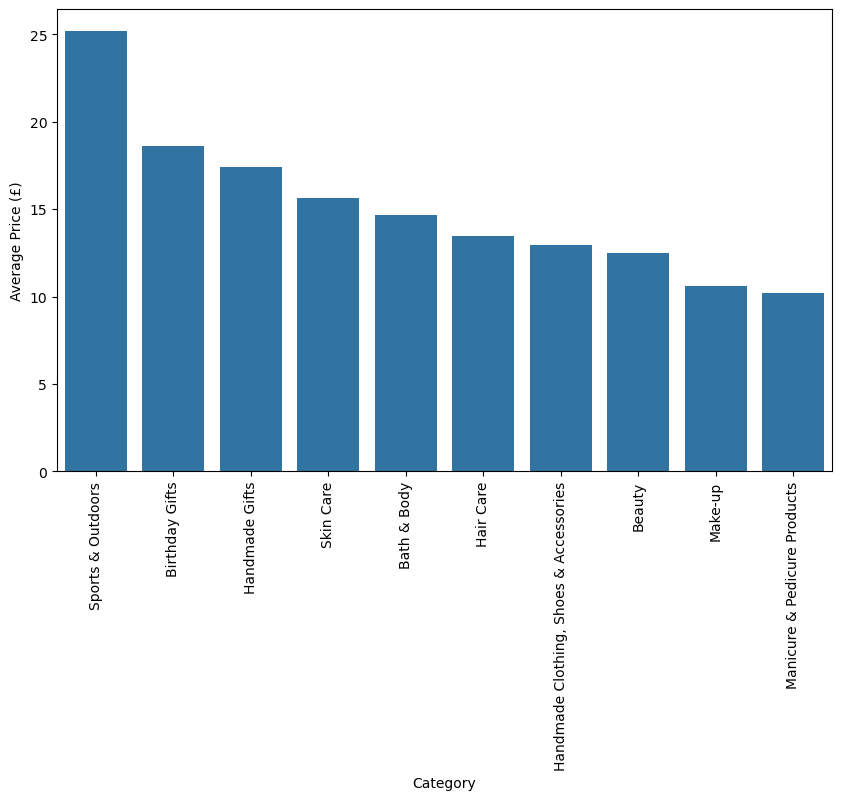

In [41]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=avg_price.index,
    y=avg_price.values
)
plt.xticks(rotation=90)
plt.xlabel("Category")
plt.ylabel("Average Price (£)")

Which product category commands the highest average price? Don't filter here by top categories.

In [42]:
avg_price.head(1)

category
Sports & Outdoors    25.172065
Name: price, dtype: float64

2.3. Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

/var/folders/c0/b40y5t4n3mn_4jcw8gjbz1zm0000gn/T/ipykernel_4975/2591590716.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data =df_top10, x = "stars", y = "category", palette= "coolwarm")


<Axes: xlabel='stars', ylabel='category'>

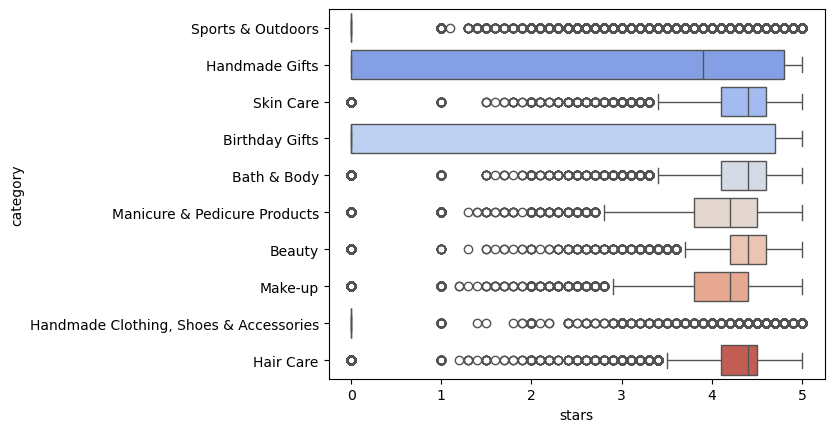

In [43]:
sns.boxplot(data =df_top10, x = "stars", y = "category", palette= "coolwarm")

Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [44]:
median_rating = (
    df_no_outliers
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating.head(1)

category
Computer Memory    4.7
Name: stars, dtype: float64

Part 3: Investigating the Interplay Between Product Prices and Ratings

3.1.Correlation Coefficients:

Calculate the correlation coefficient between price and stars.

In [45]:
df["price"].corr(df["stars"])

np.float64(-0.12490673262148537)

In [46]:
df["price"].corr(df["stars"], method = "spearman")

np.float64(-0.13316425462433998)

Is there a significant correlation between product price and its rating?

Both Pearson (-0.125) and Spearman (-0.133) correlations coefficients indicate a very weak negative relationship between product price and customer rating. There is a slight tendency for higher-priced products to receive lower ratings, but the relationship is very weak.

3.2. Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

<Axes: xlabel='stars', ylabel='price'>

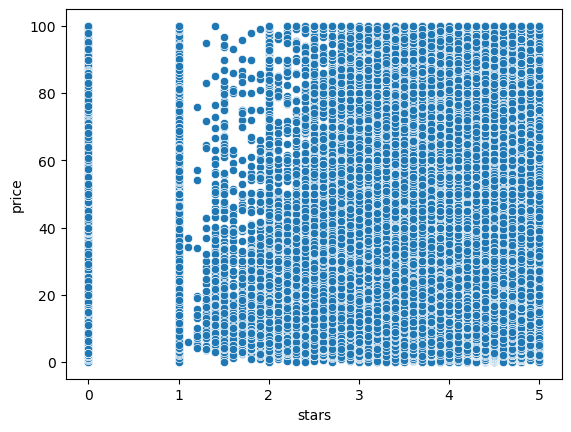

In [52]:
sns.scatterplot(data = df_no_outliers, x= "stars", y = "price")

The scatter plot shows no clear relationship between product price and customer ratings. Products with similar prices receive a wide range of ratings, and highly rated products can be found across all price levels. This visual pattern is consistent with the very weak negative Pearson and Spearman correlation coefficients.

Use a correlation heatmap to visualize correlations between all numerical variables.


In [56]:
df_numerical = df_no_outliers.select_dtypes("number")

df_numerical.corrwith(df_no_outliers["price"])

uid                  0.001717
stars               -0.077673
reviews             -0.008498
price                1.000000
boughtInLastMonth   -0.059051
dtype: float64

In [59]:
matrix = df_numerical.corr()
matrix

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.030288,0.020236,0.001717,0.017116
stars,0.030288,1.000000,0.083920,-0.077673,0.113994
reviews,0.020236,0.083920,1.000000,-0.008498,0.105624
price,0.001717,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.017116,0.113994,0.105624,-0.059051,1.000000


<Axes: >

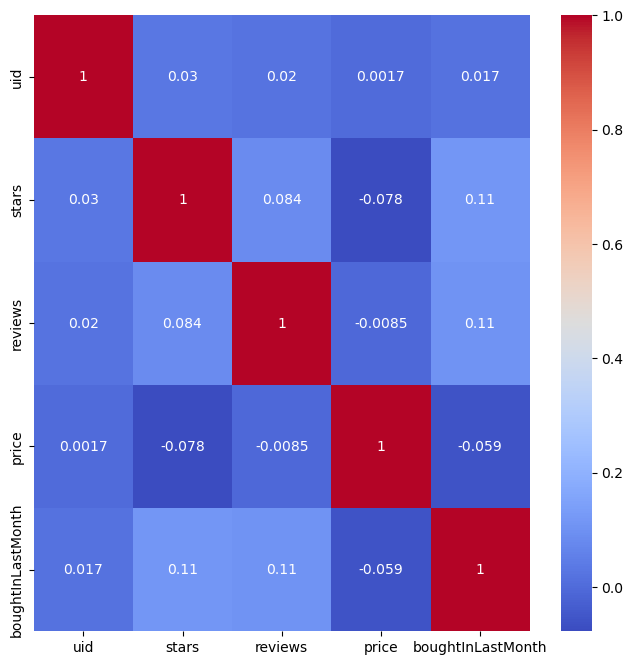

In [60]:
plt.figure(figsize=(8, 8))

sns.heatmap(matrix, annot = True, cmap = "coolwarm")


As already seen, the heatmap shows that there are no strong correlations between the numerical variables. All correlation coefficients are close to 0, suggesting weak linear relationships. The strongest correlations are between stars and boughtInLastMonth (0.11), and between reviews and boughtInLastMonth (0.11), but both remain weak.